In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast

plt.style.use('default')

In [2]:
sns.set_palette("husl")
palette = sns.color_palette("husl")


In [3]:
df = pd.read_csv('data/methods.tsv', sep='\t', header=None)
df.columns = ['Unnamed: 0', 'precision', 'recall', 'f1-score', 'support', 'split', 'method', 'hash', 'method_params', 'task', 'epoch']
df = df[df['Unnamed: 0'] == 'accuracy'].copy()
df['accuracy'] = pd.to_numeric(df['precision'], errors='coerce')
df['method_params'] = df['method_params'].apply(lambda x: str(x) if not isinstance(x, str) else x)
df

,Unnamed: 0,precision,recall,f1-score,support,split,method,hash,method_params,task,epoch,accuracy
4,accuracy,0.625,0.625,0.625,0.625,0,ct_pb_mr,005e1b053d,{'norm': 0},pbmc_scgpt,NaN,0.625000
10,accuracy,0.875,0.875,0.875,0.875,1,ct_pb_mr,005e1b053d,{'norm': 0},pbmc_scgpt,NaN,0.875000
16,accuracy,0.25,0.25,0.25,0.25,2,ct_pb_mr,005e1b053d,{'norm': 0},pbmc_scgpt,NaN,0.250000
22,accuracy,0.5,0.5,0.5,0.5,3,ct_pb_mr,005e1b053d,{'norm': 0},pbmc_scgpt,NaN,0.500000
28,accuracy,0.2857142857142857,0.2857142857142857,0.2857142857142857,0.2857142857142857,4,ct_pb_mr,005e1b053d,{'norm': 0},pbmc_scgpt,NaN,0.285714
...,...,...,...,...,...,...,...,...,...,...,...,...
19887,accuracy,0.7628292224080268,0.7628292224080268,0.7628292224080268,0.7628292224080268,0,multigrate_mil_reg,ffb98046f8,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",pbmc_pca,49.0,0.762829
19893,accuracy,0.8706462414638648,0.8706462414638648,0.8706462414638648,0.8706462414638648,1,multigrate_mil_reg,ffb98046f8,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",pbmc_pca,49.0,0.870646
19899,accuracy,0.6997659061528249,0.6997659061528249,0.6997659061528249,0.6997659061528249,2,multigrate_mil_reg,ffb98046f8,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",pbmc_pca,49.0,0.699766
19905,accuracy,0.8748167283390351,0.8748167283390351,0.8748167283390351,0.8748167283390351,3,multigrate_mil_reg,ffb98046f8,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",pbmc_pca,49.0,0.874817


In [4]:
# Only keep configs with all 5 splits
split_counts = df.groupby(['hash', 'method', 'task', 'epoch', 'method_params'])['split'].nunique().reset_index()
full_configs = split_counts[split_counts['split'] == 5]
df_full = pd.merge(df, full_configs.drop('split', axis=1), on=['hash', 'method', 'task', 'epoch', 'method_params'])
df_full 

,Unnamed: 0,precision,recall,f1-score,support,split,method,hash,method_params,task,epoch,accuracy
0,accuracy,0.8703752090301003,0.8703752090301003,0.8703752090301003,0.8703752090301003,0,multigrate_mil_reg,00eb5dd690,"{'lr': 1e-05, 'categorical_covariate_keys': ""[...",pbmc_scvi,99.0,0.870375
1,accuracy,0.7779,0.7779,0.7779,0.7779,0,multigrate_mil_reg,00eb5dd690,"{'lr': 1e-05, 'categorical_covariate_keys': ""[...",pbmc_scvi,49.0,0.777900
2,accuracy,0.698605215281989,0.698605215281989,0.698605215281989,0.698605215281989,1,multigrate_mil_reg,00eb5dd690,"{'lr': 1e-05, 'categorical_covariate_keys': ""[...",pbmc_scvi,49.0,0.698605
3,accuracy,0.79375,0.79375,0.79375,0.79375,1,multigrate_mil_reg,00eb5dd690,"{'lr': 1e-05, 'categorical_covariate_keys': ""[...",pbmc_scvi,99.0,0.793750
4,accuracy,0.6731770378393487,0.6731770378393487,0.6731770378393487,0.6731770378393487,2,multigrate_mil_reg,00eb5dd690,"{'lr': 1e-05, 'categorical_covariate_keys': ""[...",pbmc_scvi,49.0,0.673177
...,...,...,...,...,...,...,...,...,...,...,...,...
2020,accuracy,0.7628292224080268,0.7628292224080268,0.7628292224080268,0.7628292224080268,0,multigrate_mil_reg,ffb98046f8,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",pbmc_pca,49.0,0.762829
2021,accuracy,0.8706462414638648,0.8706462414638648,0.8706462414638648,0.8706462414638648,1,multigrate_mil_reg,ffb98046f8,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",pbmc_pca,49.0,0.870646
2022,accuracy,0.6997659061528249,0.6997659061528249,0.6997659061528249,0.6997659061528249,2,multigrate_mil_reg,ffb98046f8,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",pbmc_pca,49.0,0.699766
2023,accuracy,0.8748167283390351,0.8748167283390351,0.8748167283390351,0.8748167283390351,3,multigrate_mil_reg,ffb98046f8,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",pbmc_pca,49.0,0.874817


In [5]:
grouped = df_full.groupby(['hash', 'method', 'task', 'epoch', 'method_params'])['accuracy'].agg(['mean', 'std']).reset_index()
grouped = grouped.rename(columns={'mean': 'accuracy', 'std': 'accuracy_std'})
grouped

,hash,method,task,epoch,method_params,accuracy,accuracy_std
0,00eb5dd690,multigrate_mil_reg,pbmc_scvi,49.0,"{'lr': 1e-05, 'categorical_covariate_keys': ""[...",0.668339,0.138927
1,00eb5dd690,multigrate_mil_reg,pbmc_scvi,99.0,"{'lr': 1e-05, 'categorical_covariate_keys': ""[...",0.762533,0.070720
2,0182946e8e,multigrate_mil,pbmc_scvi,49.0,"{'lr': 0.001, 'categorical_covariate_keys': ""[...",0.746079,0.152377
3,026607420a,multigrate_mil_reg,pbmc_pca,49.0,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",0.735984,0.101544
4,033d71d5d8,multigrate_mil_reg,pbmc_scgpt,49.0,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",0.830146,0.108893
...,...,...,...,...,...,...,...
400,fd366ff6dd,multigrate_mil_reg,pbmc_scvi,49.0,"{'lr': 0.001, 'categorical_covariate_keys': ""[...",0.805855,0.111561
401,ff42efd560,multigrate_mil_reg,pbmc_geneformer,49.0,"{'lr': 0.001, 'categorical_covariate_keys': ""[...",0.730905,0.092908
402,ff47e10c71,multigrate_mil_reg,pbmc_scvi,49.0,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",0.789891,0.101950
403,ff4c8523a5,multigrate_mil,pbmc_scgpt,49.0,"{'lr': 0.01, 'categorical_covariate_keys': ""['...",0.756898,0.142494


In [11]:
task_order = ['pbmc_scvi', 'pbmc_scgpt', 'pbmc_pca', 'pbmc_geneformer']
tasks = [t for t in task_order if t in grouped['task'].unique()]
methods = grouped['method'].unique()
top5 = grouped.groupby(['method', 'task']).apply(lambda x: x.nlargest(5, 'accuracy')).reset_index(drop=True)

/tmp/ipykernel_897879/3857631826.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  top5 = grouped.groupby(['method', 'task']).apply(lambda x: x.nlargest(5, 'accuracy')).reset_index(drop=True)


In [12]:
top5

,hash,method,task,epoch,method_params,accuracy,accuracy_std
0,54290c7cbc,multigrate_mil,pbmc_geneformer,49.0,"{'lr': 0.001, 'categorical_covariate_keys': ""[...",0.744112,0.080521
1,ab29651ecc,multigrate_mil,pbmc_geneformer,49.0,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",0.739710,0.125087
2,7a8bc39e35,multigrate_mil,pbmc_geneformer,49.0,"{'lr': 0.01, 'categorical_covariate_keys': ""['...",0.734856,0.070941
3,59e95c1119,multigrate_mil,pbmc_geneformer,49.0,"{'lr': 0.0001, 'categorical_covariate_keys': ""...",0.719090,0.149168
4,83fe2cea62,multigrate_mil,pbmc_geneformer,49.0,"{'lr': 0.01, 'categorical_covariate_keys': ""['...",0.710806,0.106410
5,4ae6416b30,multigrate_mil,pbmc_pca,49.0,"{'lr': 0.01, 'categorical_covariate_keys': ""['...",0.752059,0.142213
6,a4ee29737a,multigrate_mil,pbmc_pca,49.0,"{'lr': 1e-05, 'categorical_covariate_keys': ""[...",0.749387,0.138037
7,34ecd697eb,multigrate_mil,pbmc_pca,49.0,"{'lr': 0.01, 'categorical_covariate_keys': ""['...",0.748905,0.160332
8,becca16f35,multigrate_mil,pbmc_pca,49.0,"{'lr': 0.01, 'categorical_covariate_keys': ""['...",0.740991,0.144526
9,1f66ccd839,multigrate_mil,pbmc_pca,49.0,"{'lr': 0.01, 'categorical_covariate_keys': ""['...",0.731895,0.132940


In [13]:
task_top5_means = {method: [top5[(top5['method'] == method) & (top5['task'] == task)]['accuracy'].mean() for task in tasks] for method in methods}
task_top5_stds = {method: [top5[(top5['method'] == method) & (top5['task'] == task)]['accuracy'].std() for task in tasks] for method in methods}
task_top5_means, task_top5_stds

({'multigrate_mil_reg': [0.823582295704662,
   0.8354650612547875,
   0.8306273430476088,
   0.8044980302402435],
  'multigrate_mil': [0.8134132842887676,
   0.803851264363883,
   0.7446473451007515,
   0.7297148702762195]},
 {'multigrate_mil_reg': [0.009479351167673929,
   0.00907570248854015,
   0.015823190929535897,
   0.009890378515912603],
  'multigrate_mil': [0.010327773870123182,
   0.008149997849906481,
   0.008239002224773263,
   0.0141777245306697]})

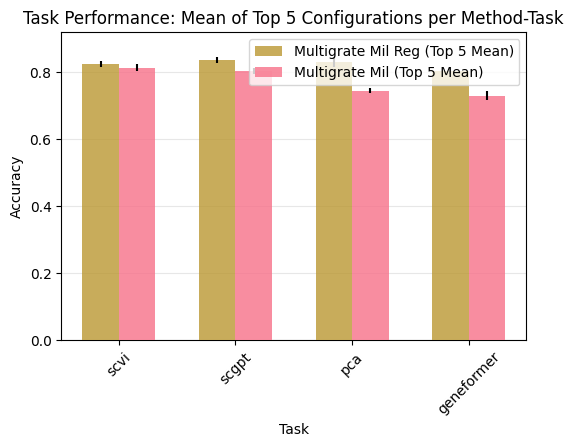

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(6, 4))
x = np.arange(len(tasks)) * 0.8
width = 0.25
bars1 = ax.bar(x - width/2, task_top5_means[methods[0]], width, yerr=task_top5_stds[methods[0]], label=f'{methods[0].replace("_", " ").title()} (Top 5 Mean)', alpha=0.8, zorder=3, color=palette[1])
bars2 = ax.bar(x + width/2, task_top5_means[methods[1]], width, yerr=task_top5_stds[methods[1]], label=f'{methods[1].replace("_", " ").title()} (Top 5 Mean)', alpha=0.8, zorder=3, color=palette[0])
ax.set_title('Task Performance: Mean of Top 5 Configurations per Method-Task')
ax.set_ylabel('Accuracy')
ax.set_xlabel('Task')
ax.set_xticks(x)
ax.set_xticklabels([t.replace('pbmc_', '') for t in tasks], rotation=45)
ax.legend()
ax.grid(True, alpha=0.3, axis='y', zorder=0)
all_values = task_top5_means[methods[0]] + task_top5_means[methods[1]]
ax.set_ylim(0, max(all_values) * 1.1)

plt.savefig('figures/top5_task_performance.svg', dpi=300, bbox_inches='tight')
plt.show()

In [15]:
stability_data = {method: [top5[(top5['method'] == method) & (top5['task'] == task)]['accuracy_std'].mean() for task in tasks] for method in methods}
stability_std = {method: [top5[(top5['method'] == method) & (top5['task'] == task)]['accuracy_std'].std() for task in tasks] for method in methods}
stability_data, stability_std

({'multigrate_mil_reg': [0.10054194140674108,
   0.11488922416953976,
   0.10396965351659368,
   0.07726292266716135],
  'multigrate_mil': [0.15692100557465843,
   0.15085196144091811,
   0.14360963297986645,
   0.10642523378299884]},
 {'multigrate_mil_reg': [0.0060673913243397565,
   0.012358129577509867,
   0.01421651940588688,
   0.020532962398782863],
  'multigrate_mil': [0.02108587437988788,
   0.015812596412521803,
   0.010335614992097304,
   0.032036657899680764]})

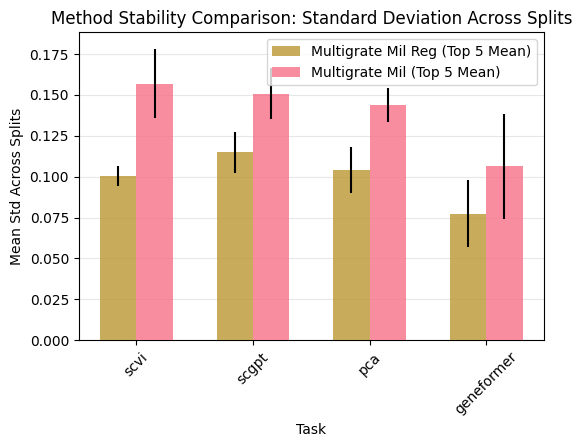

In [18]:
fig, ax = plt.subplots(1, 1, figsize=(6, 4))
x = np.arange(len(tasks)) * 0.8
width = 0.25
bars1 = ax.bar(x - width/2, stability_data[methods[0]], width, yerr=stability_std[methods[0]], label=f'{methods[0].replace("_", " ").title()} (Top 5 Mean)', alpha=0.8, zorder=3, color=palette[1])
bars2 = ax.bar(x + width/2, stability_data[methods[1]], width, yerr=stability_std[methods[1]], label=f'{methods[1].replace("_", " ").title()} (Top 5 Mean)', alpha=0.8, zorder=3, color=palette[0])
ax.set_title('Method Stability Comparison: Standard Deviation Across Splits')
ax.set_ylabel('Mean Std Across Splits')
ax.set_xlabel('Task')
ax.set_xticks(x)
ax.set_xticklabels([t.replace('pbmc_', '') for t in tasks], rotation=45)
ax.legend()
ax.grid(True, alpha=0.3, axis='y', zorder=0)
all_values = stability_data[methods[0]] + stability_data[methods[1]]
ax.set_ylim(0, max(all_values) * 1.2)

plt.savefig('figures/stability_comparison.svg', dpi=300, bbox_inches='tight')
plt.show()